## Question 1 — Implement Convolution from Scratch


In [2]:
# Import NumPy for working with arrays
import numpy as np

In [3]:
# Store the 5x5 input matrix as a NumPy array
input_matrix = np.array([
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0],
    [0, 1, 1, 0, 0]
])

print("Input Matrix:")
print(input_matrix)

Input Matrix:
[[1 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 1]
 [0 0 1 1 0]
 [0 1 1 0 0]]


In [4]:
# Store the 3x3 filter as a NumPy array
filter_matrix = np.array([
    [1, 0, 1],
    [0, 1, 0],
    [1, 0, 1]
])

print("Filter:")
print(filter_matrix)

Filter:
[[1 0 1]
 [0 1 0]
 [1 0 1]]


In [5]:
# Set the stride and padding values given in the question
stride = 1
padding = 0

In [6]:
# Get the dimensions of the input matrix and filter
input_height, input_width = input_matrix.shape
filter_height, filter_width = filter_matrix.shape

# Calculate the dimensions of the output feature map
output_height = ((input_height - filter_height + 2 * padding) // stride) + 1
output_width = ((input_width - filter_width + 2 * padding) // stride) + 1

print("Output Height:", output_height)
print("Output Width:", output_width)

Output Height: 3
Output Width: 3


In [7]:
# Create an empty output feature map
output = np.zeros((output_height, output_width), dtype=int)

# Slide the filter over every valid location in the input matrix
for i in range(output_height):
    for j in range(output_width):
        
        # Find the starting row and column based on the stride
        row_start = i * stride
        col_start = j * stride
        
        # Extract the region of the input covered by the filter
        region = input_matrix[
            row_start:row_start + filter_height,
            col_start:col_start + filter_width
        ]
        
        # Multiply corresponding elements and add them together
        output[i, j] = np.sum(region * filter_matrix)

In [8]:
# Print the complete output feature map
print("Output Feature Map:")
print(output)

# Print the shape of the output feature map
print("Output Shape:", output.shape)

Output Feature Map:
[[4 3 4]
 [2 4 3]
 [2 3 4]]
Output Shape: (3, 3)


Changing the stride from 1 to 2 reduces the number of filter positions, making the output feature map smaller.

# Question 2 — Transfer Learning: Freeze vs. Fine-Tune

In [9]:
# Import required libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import time

In [26]:
# Define image transformations for ResNet18
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load the CIFAR-10 training dataset
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Load the CIFAR-10 test dataset
test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Display dataset information
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset.classes)

Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [15]:
# Create DataLoaders for training and testing
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

Training batches: 1563
Test batches: 313


## Experiment A — Feature Extraction

In [16]:
# Load a pretrained ResNet18 model
model_A = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all pretrained layers
for param in model_A.parameters():
    param.requires_grad = False

# Replace the final classification layer for the 10 CIFAR-10 classes
num_features = model_A.fc.in_features
model_A.fc = nn.Linear(num_features, 10)

# Count the number of trainable parameters
trainable_params_A = sum(
    p.numel() for p in model_A.parameters() if p.requires_grad
)

print("Trainable Parameters:", trainable_params_A)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/yousefaldandani/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 41.7MB/s]

Trainable Parameters: 5130


In [17]:
# Select the available device
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model_A = model_A.to(device)

print("Device:", device)

Device: mps


In [18]:
# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()

# Optimize only the trainable parameters
optimizer_A = optim.Adam(
    filter(lambda p: p.requires_grad, model_A.parameters()),
    lr=0.001
)

# Use the same number of epochs for both experiments
num_epochs = 5

# Store training loss for each epoch
losses_A = []

# Start measuring training time
start_time = time.time()

# Train the model
for epoch in range(num_epochs):
    model_A.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer_A.zero_grad()

        # Forward pass
        outputs = model_A(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update the classifier parameters
        optimizer_A.step()

        running_loss += loss.item()

    # Calculate average loss for this epoch
    epoch_loss = running_loss / len(train_loader)
    losses_A.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs}, "
        f"Loss: {epoch_loss:.4f}"
    )

# Record total training time
training_time_A = time.time() - start_time

print(f"Training Time: {training_time_A:.2f} seconds")

Epoch 1/5, Loss: 0.8019
Epoch 2/5, Loss: 0.6402
Epoch 3/5, Loss: 0.6141
Epoch 4/5, Loss: 0.6104
Epoch 5/5, Loss: 0.5997
Training Time: 1461.21 seconds


In [19]:
# Evaluate Experiment A on the test dataset
model_A.eval()

correct = 0
total = 0

# Disable gradient calculations during testing
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Make predictions
        outputs = model_A(images)
        _, predicted = torch.max(outputs, 1)

        # Count correct predictions
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

# Calculate test accuracy
accuracy_A = 100 * correct / total

print(f"Test Accuracy: {accuracy_A:.2f}%")

Test Accuracy: 80.79%


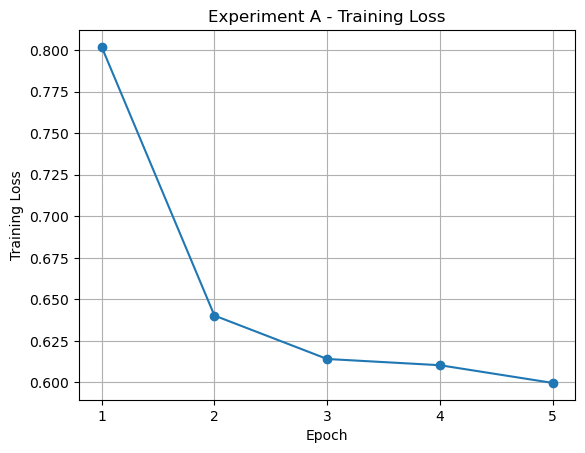

In [20]:
# Plot the training loss for Experiment A
plt.plot(range(1, num_epochs + 1), losses_A, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Experiment A - Training Loss")
plt.xticks(range(1, num_epochs + 1))
plt.grid(True)

plt.show()

## Experiment B — Fine-Tuning

In [22]:
# Load a new pretrained ResNet18 model
model_B = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all pretrained layers first
for param in model_B.parameters():
    param.requires_grad = False

# Unfreeze the last convolutional block
for param in model_B.layer4.parameters():
    param.requires_grad = True

# Replace the final classification layer for the 10 CIFAR-10 classes
num_features = model_B.fc.in_features
model_B.fc = nn.Linear(num_features, 10)

# Count the number of trainable parameters
trainable_params_B = sum(
    p.numel() for p in model_B.parameters() if p.requires_grad
)

# Move the model to the same device
model_B = model_B.to(device)

print("Trainable Parameters:", trainable_params_B)
print("Device:", device)

Trainable Parameters: 8398858
Device: mps


In [23]:
# Define the optimizer for the unfrozen layers and classifier
optimizer_B = optim.Adam(
    filter(lambda p: p.requires_grad, model_B.parameters()),
    lr=0.0001
)

# Store training loss for each epoch
losses_B = []

# Start measuring training time
start_time = time.time()

# Train the fine-tuned model
for epoch in range(num_epochs):
    model_B.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer_B.zero_grad()

        # Forward pass
        outputs = model_B(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update the unfrozen parameters
        optimizer_B.step()

        running_loss += loss.item()

    # Calculate average loss for this epoch
    epoch_loss = running_loss / len(train_loader)
    losses_B.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs}, "
        f"Loss: {epoch_loss:.4f}"
    )

# Record total training time
training_time_B = time.time() - start_time

print(f"Training Time: {training_time_B:.2f} seconds")

Epoch 1/5, Loss: 0.4311
Epoch 2/5, Loss: 0.1608
Epoch 3/5, Loss: 0.0711
Epoch 4/5, Loss: 0.0412
Epoch 5/5, Loss: 0.0347
Training Time: 1948.62 seconds


In [24]:
# Evaluate Experiment B on the test dataset
model_B.eval()

correct = 0
total = 0

# Disable gradient calculations during testing
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Make predictions
        outputs = model_B(images)
        _, predicted = torch.max(outputs, 1)

        # Count correct predictions
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

# Calculate test accuracy
accuracy_B = 100 * correct / total

print(f"Test Accuracy: {accuracy_B:.2f}%")

Test Accuracy: 90.35%


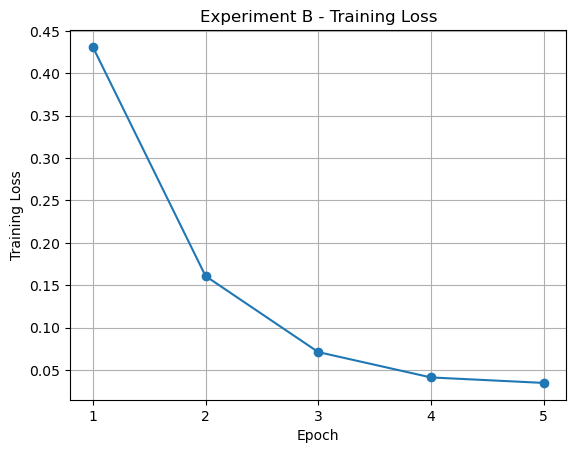

In [25]:
# Plot the training loss for Experiment B
plt.plot(range(1, num_epochs + 1), losses_B, marker='o')

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Experiment B - Training Loss")
plt.xticks(range(1, num_epochs + 1))
plt.grid(True)

plt.show()

### Comparison of the Two Approaches

| Method | Trainable Parameters | Training Time | Accuracy |
|---|---:|---:|---:|
| Frozen Feature Extractor | 5,130 | 1461.21 s | 80.79% |
| Fine-Tuned Network | 8,398,858 | 1948.62 s | 90.35% |

### Discussion

The frozen feature extractor achieved 80.79% accuracy, while the fine-tuned network achieved 90.35% accuracy. The frozen model had only 5,130 trainable parameters, so it required less training time. In comparison, the fine-tuned model had 8,398,858 trainable parameters and took longer to train. Fine-tuning improved accuracy because the unfrozen layers were able to adapt their learned features to the CIFAR-10 dataset. The frozen model could only update the final classifier while keeping the pretrained features unchanged. Therefore, fine-tuning provided better performance but required more computation and training time.